# Milestone 05 — Unsupervised Clustering

**Question:** What groups emerge when we compare covers by where their colors appear?

Each cover is represented by 12 features: average red, green, and blue in each of four quadrants. We will fit K-means on the same 16 training covers used in Milestone 04 and reserve the four holdout comics for later evaluation.

K-means forms groups from the feature values without using labels. We will inspect which covers land together and describe the groups using the cover images.

In [1]:
# Load the pilot catalog and recover the Milestone 04 training split
from pathlib import Path

import pandas as pd

catalog_path = Path("data/raw/metadata/comic_catalog_pilot.csv")
project_root = next(
    folder
    for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / catalog_path).is_file()
)

catalog = pd.read_csv(project_root / catalog_path)
holdout_ids = {"CV0001", "CV0002", "CV0016", "CV0018"}

holdout_mask = catalog["comic_id"].isin(holdout_ids)
train_data = catalog.loc[~holdout_mask].copy()

print("Training comics:", len(train_data))
print("Holdout IDs found:", sorted(catalog.loc[holdout_mask, "comic_id"]))

Training comics: 16
Holdout IDs found: ['CV0001', 'CV0002', 'CV0016', 'CV0018']


In [2]:
# Extract quadrant RGB features from the training covers
import numpy as np
from PIL import Image

quadrant_names = ["top_left", "top_right", "bottom_left", "bottom_right"]
feature_columns = [
    f"{quadrant}_{channel}"
    for quadrant in quadrant_names
    for channel in ["red", "green", "blue"]
]

feature_rows = []

for _, comic in train_data.iterrows():
    cover_path = project_root / comic["cover_image_path"]

    with Image.open(cover_path) as cover:
        pixels = np.asarray(cover.convert("RGB"))

    height, width, _ = pixels.shape
    mid_row = height // 2
    mid_col = width // 2

    quadrants = [
        pixels[:mid_row, :mid_col],
        pixels[:mid_row, mid_col:],
        pixels[mid_row:, :mid_col],
        pixels[mid_row:, mid_col:],
    ]

    cover_features = []
    for quadrant in quadrants:
        cover_features.extend(quadrant.mean(axis=(0, 1)))

    feature_rows.append(cover_features)

train_features = pd.DataFrame(
    feature_rows,
    index=pd.Index(train_data["comic_id"], name="comic_id"),
    columns=feature_columns,
)

print("Feature table shape:", train_features.shape)
print("Missing feature values:", train_features.isna().sum().sum())
print("\nCV0003 quadrant RGB:")
print(train_features.loc["CV0003"].to_numpy().reshape(4, 3).round(1))

Feature table shape: (16, 12)
Missing feature values: 0

CV0003 quadrant RGB:
[[176.1 154.  115.5]
 [162.3 147.5 135.9]
 [135.5 122.3 108.8]
 [155.5 137.5 121.1]]


In [3]:
# Fit K-means on the 16 training covers
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(train_features)

train_clusters = pd.Series(cluster_labels, index=train_features.index, name="cluster")

print("Training covers assigned:", len(train_clusters))
print("Covers per cluster:")
print(train_clusters.value_counts().sort_index().to_string())

Training covers assigned: 16
Covers per cluster:
cluster
0    5
1    6
2    5


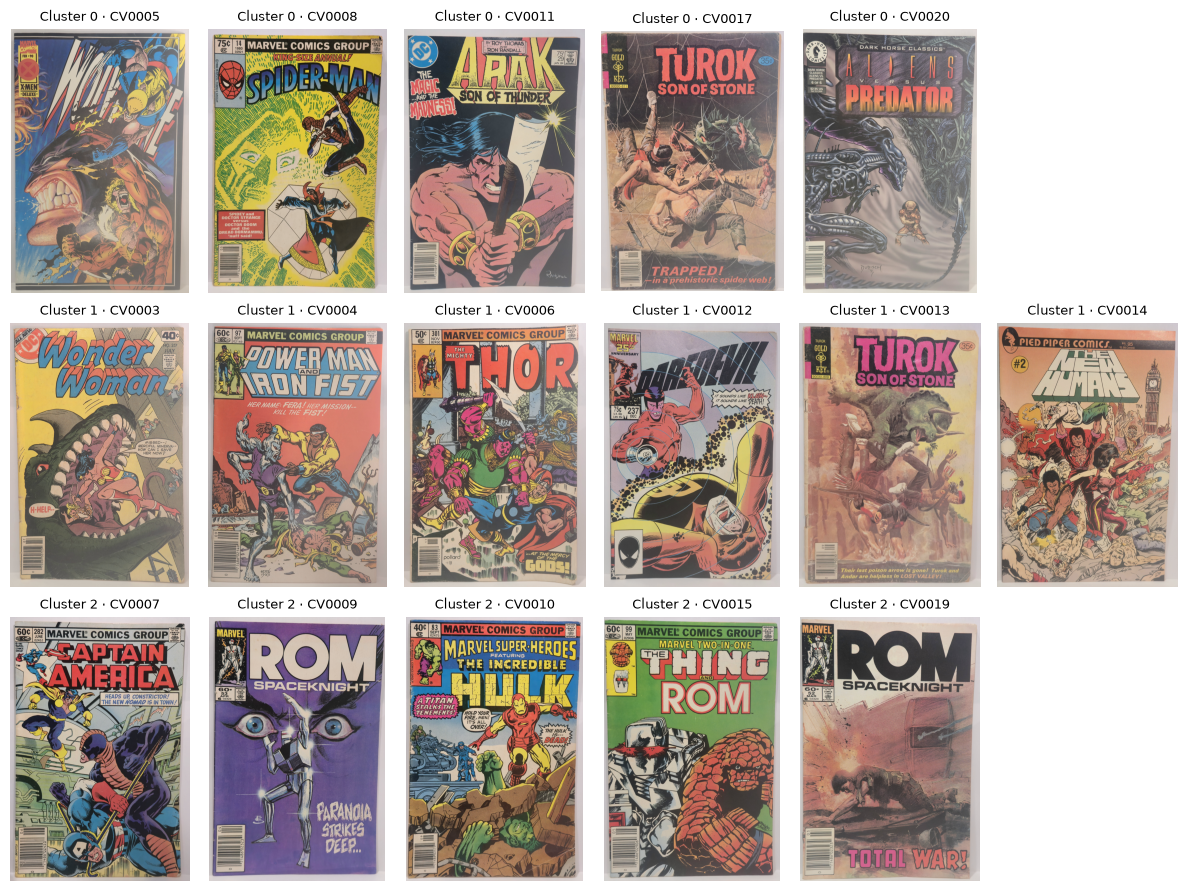

In [4]:
# Display training covers grouped by their K-means assignments
import matplotlib.pyplot as plt

cluster_ids = sorted(train_clusters.unique())
max_covers = int(train_clusters.value_counts().max())
comics_by_id = train_data.set_index("comic_id")

fig, axes = plt.subplots(
    len(cluster_ids), max_covers, figsize=(12, 9), squeeze=False
)

for cluster_id, row_axes in zip(cluster_ids, axes):
    members = train_clusters[train_clusters == cluster_id].index

    for ax in row_axes:
        ax.axis("off")

    for ax, comic_id in zip(row_axes, members):
        cover_path = project_root / comics_by_id.loc[comic_id, "cover_image_path"]
        with Image.open(cover_path) as cover:
            ax.imshow(cover.convert("RGB"))

        ax.set_title(f"Cluster {cluster_id} · {comic_id}", fontsize=9)

fig.tight_layout()
plt.show()

In [5]:
# Show the average quadrant RGB values for each cluster
for cluster_id, center in enumerate(kmeans.cluster_centers_):
    center_table = pd.DataFrame(
        center.reshape(4, 3),
        index=quadrant_names,
        columns=["Red", "Green", "Blue"],
    )

    print(f"\nCluster {cluster_id}")
    print(center_table.round(1).to_string())


Cluster 0
                Red  Green   Blue
top_left      127.9  115.7  103.6
top_right     143.4  130.2  117.2
bottom_left   160.5  141.5  125.5
bottom_right  161.4  143.8  128.2

Cluster 1
                Red  Green   Blue
top_left      162.2  130.9  114.8
top_right     169.5  144.2  133.6
bottom_left   150.6  130.1  115.9
bottom_right  162.1  140.4  125.8

Cluster 2
                Red  Green   Blue
top_left      139.5  127.7  116.0
top_right     142.9  129.5  121.1
bottom_left   128.6  117.5  115.9
bottom_right  133.0  111.5  109.6


In [6]:
# Compare cluster separation and sizes on the training covers
from sklearn.metrics import silhouette_score

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(train_features)

    score = silhouette_score(train_features, labels)
    sizes = pd.Series(labels).value_counts().sort_index().tolist()

    print(f"k={k} | silhouette={score:.3f} | cluster sizes={sizes}")

k=2 | silhouette=0.249 | cluster sizes=[11, 5]
k=3 | silhouette=0.260 | cluster sizes=[5, 6, 5]
k=4 | silhouette=0.275 | cluster sizes=[1, 5, 6, 4]
k=5 | silhouette=0.285 | cluster sizes=[6, 4, 4, 1, 1]


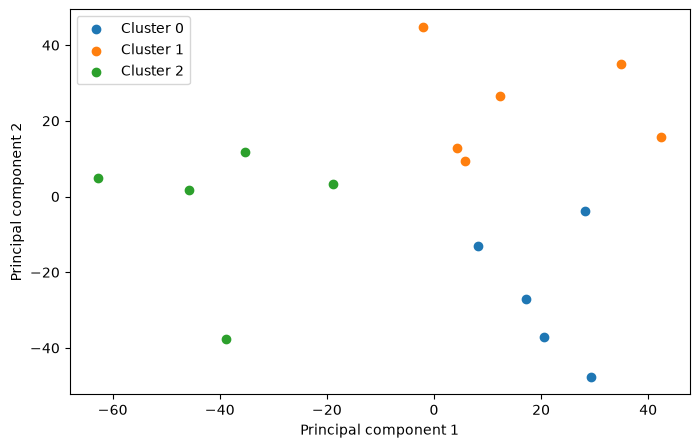

Variation captured by both axes: 62.4%


In [7]:
# Visualize the existing clusters in two dimensions
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coordinates = pca.fit_transform(train_features)

fig, ax = plt.subplots(figsize=(8, 5))

for cluster_id in sorted(train_clusters.unique()):
    members = train_clusters.to_numpy() == cluster_id
    ax.scatter(
        coordinates[members, 0],
        coordinates[members, 1],
        label=f"Cluster {cluster_id}",
    )

ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.legend()
plt.show()

print(f"Variation captured by both axes: {pca.explained_variance_ratio_.sum():.1%}")

### Interpreting the three-cluster result

We kept three clusters for this exploratory analysis. The groups contain 5, 6, and 5 training covers, with a silhouette score of 0.260. Five clusters scored higher (0.285) and produced two groups containing one cover each. Three clusters gave us multiple covers in every group to compare.

The PCA plot captures 62.4% of the variation in the 12 quadrant RGB features. Cluster 2 appears mostly to the left, while clusters 0 and 1 separate mainly along the vertical axis. The remaining 37.6% of the feature variation lies outside this view.

These groups describe color patterns in the 16 training covers. The four holdout covers remain reserved for later evaluation.